# Project 1: VaR and ES -- Estimation, Backtesting, and Model Comparison

**Names of all group members:**
- Dario Frey (dario.frey@epfl.ch)
- Léo Wunderli (leo.wunderli@epfl.ch)
- Romain Fastenaekels (romain.fastenaekels@epfl.ch)
- Enzo Cassini-Peloux (enzo.cassini@epfl.ch)
---

## 0) Setup

Creates necessary folders, sets parameters, and fixes the random seed. Keep this seed fixed; the whole run must be reproducible from it.

In [1]:
# If a package import fails, install it in your environment, e.g.:
# %pip install arch statsmodels

import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_FILE = PROJECT_DIR / "QRM_2026_Project_prices.csv"   # provided with the project; do not re-download
OUT_DIR = PROJECT_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameters
TICKERS = ["AAPL", "META", "JPM"]   # every question is run separately on each stock
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
DEEP_ALPHA = 0.999                  # Question 6: the extreme level EVT is asked for
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples
LB_LAGS = 10                        # Ljung-Box H in Questions 1 and 4
NW_LAGS = 10                        # Newey-West truncation lag of the Diebold-Mariano test
SEED = 0                            # fix this, state it in the report, do not change it later

rng = np.random.default_rng(SEED)
print("Project dir:", PROJECT_DIR)


Project dir: /Users/romain/Documents/Epfl/MA3/quant_risk/QRM_project


## 1) Data

The prices were downloaded once with `yfinance` (adjusted closes, 2 January 2013 to 30 June 2026,
downloaded on 28 October 2026) and are provided as `QRM_2026_Project_prices.csv`. Read this file;
do not download the data again, since Yahoo revises adjusted prices back in time.

In [2]:
price_df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKERS]
print(price_df.shape, price_df.index[0].date(), "to", price_df.index[-1].date())   # (3393, 3)

(3393, 3) 2013-01-02 to 2026-06-30


## 2) Log-returns and losses

Construct $R_t=\log(P_t/P_{t-1})$ for each ticker. The log-loss used everywhere in this project is
$L_t=-R_t$. Every question is run separately on each of the three columns; there is no portfolio.

In [3]:
returns = np.log(price_df / price_df.shift(1)).dropna()
losses = -returns

print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())   # (3392, 3)
returns.head()

(3392, 3) 2013-01-03 to 2026-06-30


,AAPL,META,JPM
Date,,,
2013-01-03,-0.012703,-0.008248,-0.002017
2013-01-04,-0.028250,0.035029,0.017569
2013-01-07,-0.005900,0.022689,0.001101
2013-01-08,0.002688,-0.012312,0.001980
2013-01-09,-0.015752,0.051311,-0.000660


## Question 1 -- Stylized facts

For each stock: (a) plot the return series; (b) ACF of returns and of squared returns, and the
Ljung-Box test with $H$ = `LB_LAGS` on both (`statsmodels.stats.diagnostic.acorr_ljungbox`);
(c) QQ-plot and Jarque-Bera.

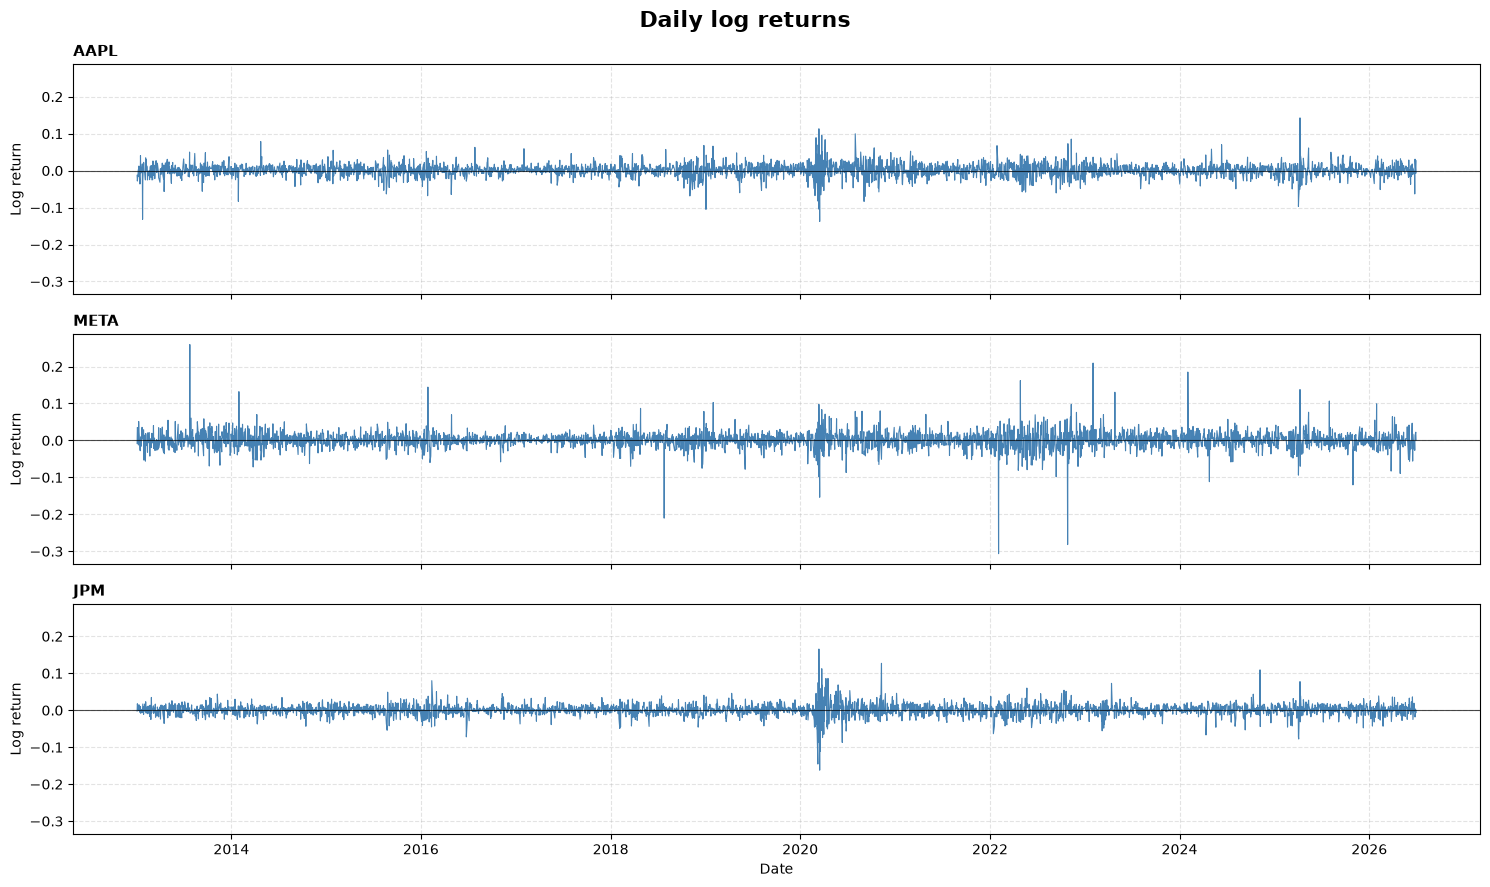

In [5]:
# Question 1

# (a)
n_series = returns.shape[1]
fig, axes = plt.subplots(
    n_series, 1,
    figsize=(15, 3 * n_series),
    sharex=True,
    sharey=True
)

plt.suptitle("Daily log returns", fontsize=16, fontweight="bold")

for ax, column in zip(axes, returns.columns):
    ax.plot(returns.index, returns[column], linewidth=0.8, color="steelblue")
    ax.axhline(0, color="black", linewidth=0.8, alpha=0.7)
    ax.set_title(str(column), loc="left", fontsize=11, fontweight="bold")
    ax.set_ylabel("Log return")
    ax.grid(True, linestyle="--", alpha=0.35)

axes[-1].set_xlabel("Date")
fig.tight_layout()
plt.savefig("output/Q1_1-stylizedfacts")
plt.show()

We observe common volatility spikes around the Covid-19 period (2020) even though JPM seems to present the highest volatility. 
Each stock otherwise present signs of independent volatilty spikes. One interesting fact on this period (2013-2026) is the number of extreme events that happened with META. 

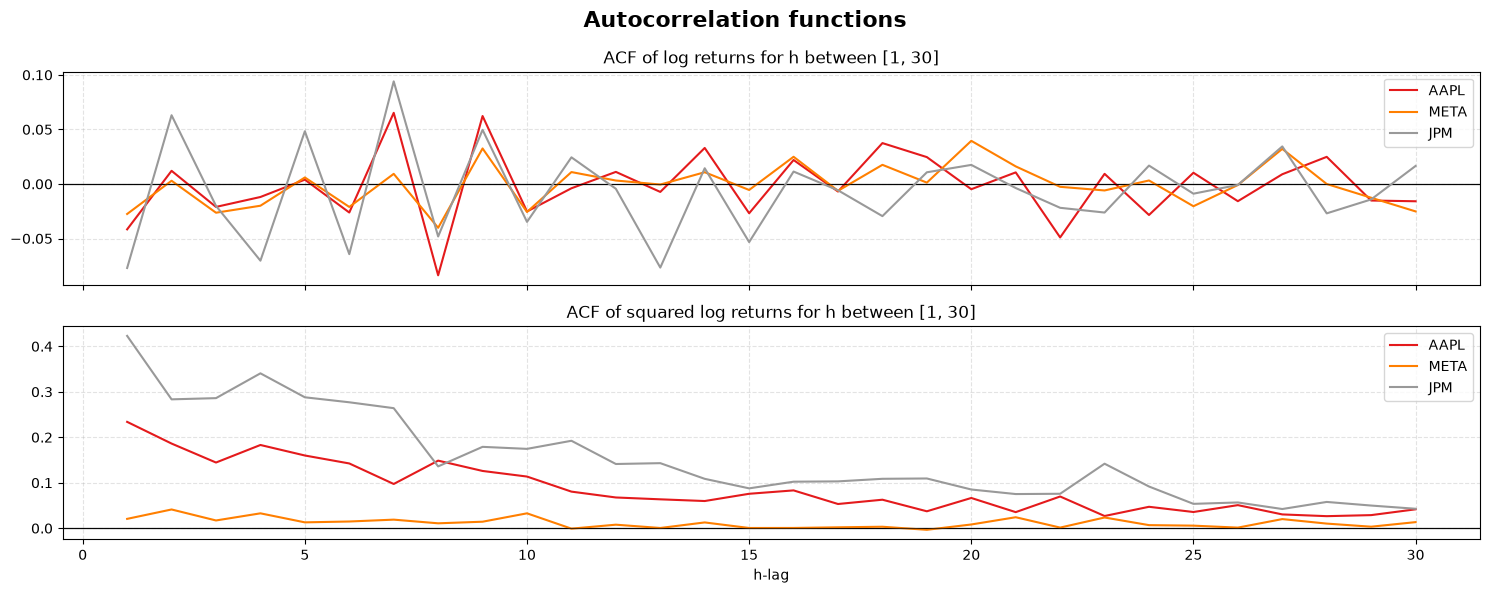

Ljung-box test - returns


,AAPL,META,JPM
lb_stat,6.443005e+01,19.576186,1.242931e+02
lb_pvalue,5.209219e-10,0.033526,6.791373e-22


Ljung-box test - squared returns


,AAPL,META,JPM
lb_stat,8.492934e+02,19.097453,2607.492719
lb_pvalue,5.179304e-176,0.039042,0.000000


In [6]:
# (b)
# We use the statsmodels acf and acorr_ljungbox methods
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

ACF = {}
ljung = {}
ljung_squared = {}

for elem in returns:
    ret = returns[elem]
    ret_2 = returns[elem] ** 2
    
    # Ljung-box test
    lj1 = acorr_ljungbox(ret, lags=[LB_LAGS]) 
    lj2 = acorr_ljungbox(ret_2, lags=[LB_LAGS])
    ljung[elem] = lj1.values.reshape(-1,)
    ljung_squared[elem] = lj2.values.reshape(-1,)
    
    acf_ret = acf(ret, nlags = 30, result_object = True)
    acf_ret_2 = acf(ret_2, nlags = 30, result_object = True)
    
    ACF[elem] = [acf_ret, acf_ret_2]
    
fig, axes = plt.subplots(
    2, 1, 
    sharex = True,
    figsize = (15, 2 * 3)
)

cmap = plt.get_cmap('Set1')
colors = [cmap(i) for i in np.linspace(0, 0.9, 3)]
plt.suptitle('Autocorrelation functions', fontsize=16, fontweight="bold")

for index, (name, value) in enumerate(ACF.items()):
    h = np.arange(1, 31, 1)
    
    for i in range(2):
        ax = axes[i]
        ax.axhline(0, color="black", linewidth=0.8, alpha=0.7)
        ax.grid(True, linestyle="--", alpha=0.35)
        
        val = value[i].acf
        ax.plot(h, val[1:], label = name, color=colors[index])
        ax.legend()
    
axes[0].set(title = 'ACF of log returns for h between [1, 30]')
axes[1].set(
    title = 'ACF of squared log returns for h between [1, 30]',
    xlabel = 'h-lag'
)
plt.tight_layout()
plt.savefig("output/Q1_2-ACF")
plt.show()
    
print('Ljung-box test - returns')
display(pd.DataFrame(ljung, index=['lb_stat', 'lb_pvalue']))
print('Ljung-box test - squared returns')
display(pd.DataFrame(ljung_squared, index=['lb_stat', 'lb_pvalue']))


The Ljung–Box test checks whether autocorrelations at lags 1 through 10 are jointly zero. We apply it separately to log returns and squared log returns. 

Rejection for returns indicates serial dependence in returns. Rejection for squared returns indicates dependence in return magnitudes, consistent with volatility clustering. We reject the null hypothesis at the 5% significance level when the p-value is below 0.05.

The ACF plots suggest weaker serial dependence for META than for AAPL and JPM. This is consistent with META’s Ljung–Box p-values being closer to the 0.05 threshold for both returns and squared returns. Nevertheless, all six p-values are below 0.05, so we reject the joint hypothesis that autocorrelations at lags 1 through 10 are zero for every stock and both series.

The ACF of log returns fluctuates around zero, with positive and negative values across the 30 lags. For squared log returns, autocorrelations are mostly positive and generally decline as the lag increases. This pattern is clear for AAPL and JPM, but weaker and less regular for META consistent with its higher pvalue. It is consistent with volatility clustering that fades over time.

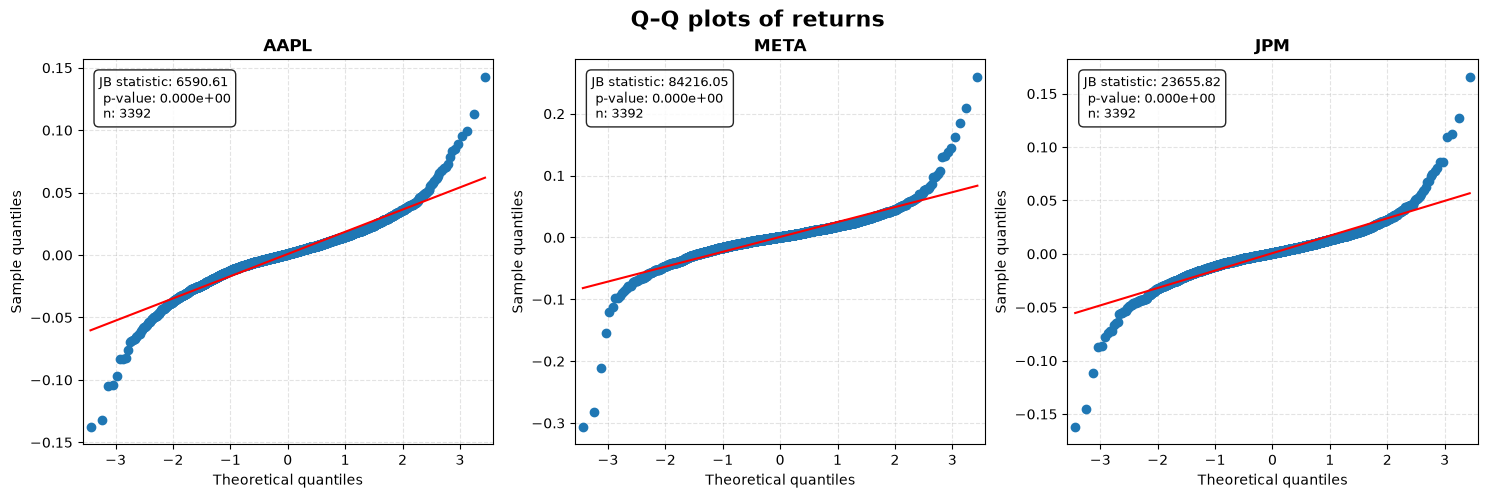

In [ ]:
# (c) 
# 1. Q-Q plot
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.stattools import jarque_bera

fig, axes = plt.subplots(
    1, 3, 
    figsize=(18, 5)
)
plt.suptitle("Q–Q plots of returns", fontsize=16, fontweight="bold")

for ax, column in zip(axes, returns.columns):
    data = returns[column].dropna()
    jb_stat, jb_pvalue, skew, kurt = jarque_bera(data)

    qqplot(data, line="s", ax=ax)
    ax.set_title(column, fontsize=12, fontweight="bold")
    ax.set_xlabel("Theoretical quantiles")
    ax.set_ylabel("Sample quantiles")
    ax.grid(True, linestyle="--", alpha=0.35)

    ax.text(
        0.04, 0.96,
        f"JB statistic: {jb_stat:.2f}\n p-value: {jb_pvalue:.3e}\n n: {len(data)}",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.85),
    )

plt.savefig("output/Q1_3-QQplot")
plt.show()


The Jarque–Bera test assesses normality using the skewness and kurtosis of returns. Its null hypothesis is that the returns follow a normal distribution (skewness of 0 and kurtosis of 3). 

For all three stocks, the p-values are below 0.05, so we reject normality at the 5% significance level. We can observe on the QQ-plot that the tails of the returns diverge heavily from a normal distribution. This is consistent with the heavy tail behavior of stock returns.

## Question 2 -- Single-window VaR and ES estimates

For each stock, use the first `WINDOW` losses as the single estimation window for (a)-(d).

,method,stock,alpha,VaR,ES
0,Historical,AAPL,0.975,0.029007,0.049743
1,Gaussian,AAPL,0.975,0.030675,0.036733
2,Student-t,AAPL,0.975,0.029466,0.042487
3,Historical,AAPL,0.990,0.038878,0.073891
4,Gaussian,AAPL,0.990,0.036549,0.041983
5,Student-t,AAPL,0.990,0.039929,0.055553
6,Historical,META,0.975,0.042346,0.055957
7,Gaussian,META,0.975,0.047198,0.056690
8,Student-t,META,0.975,0.045408,0.063511
9,Historical,META,0.990,0.053480,0.065295


,AAPL,META,JPM
nu,4.132389,4.679262,6.482710
mu,-0.001059,-0.001308,-0.000962
sigma,0.011133,0.017800,0.009737


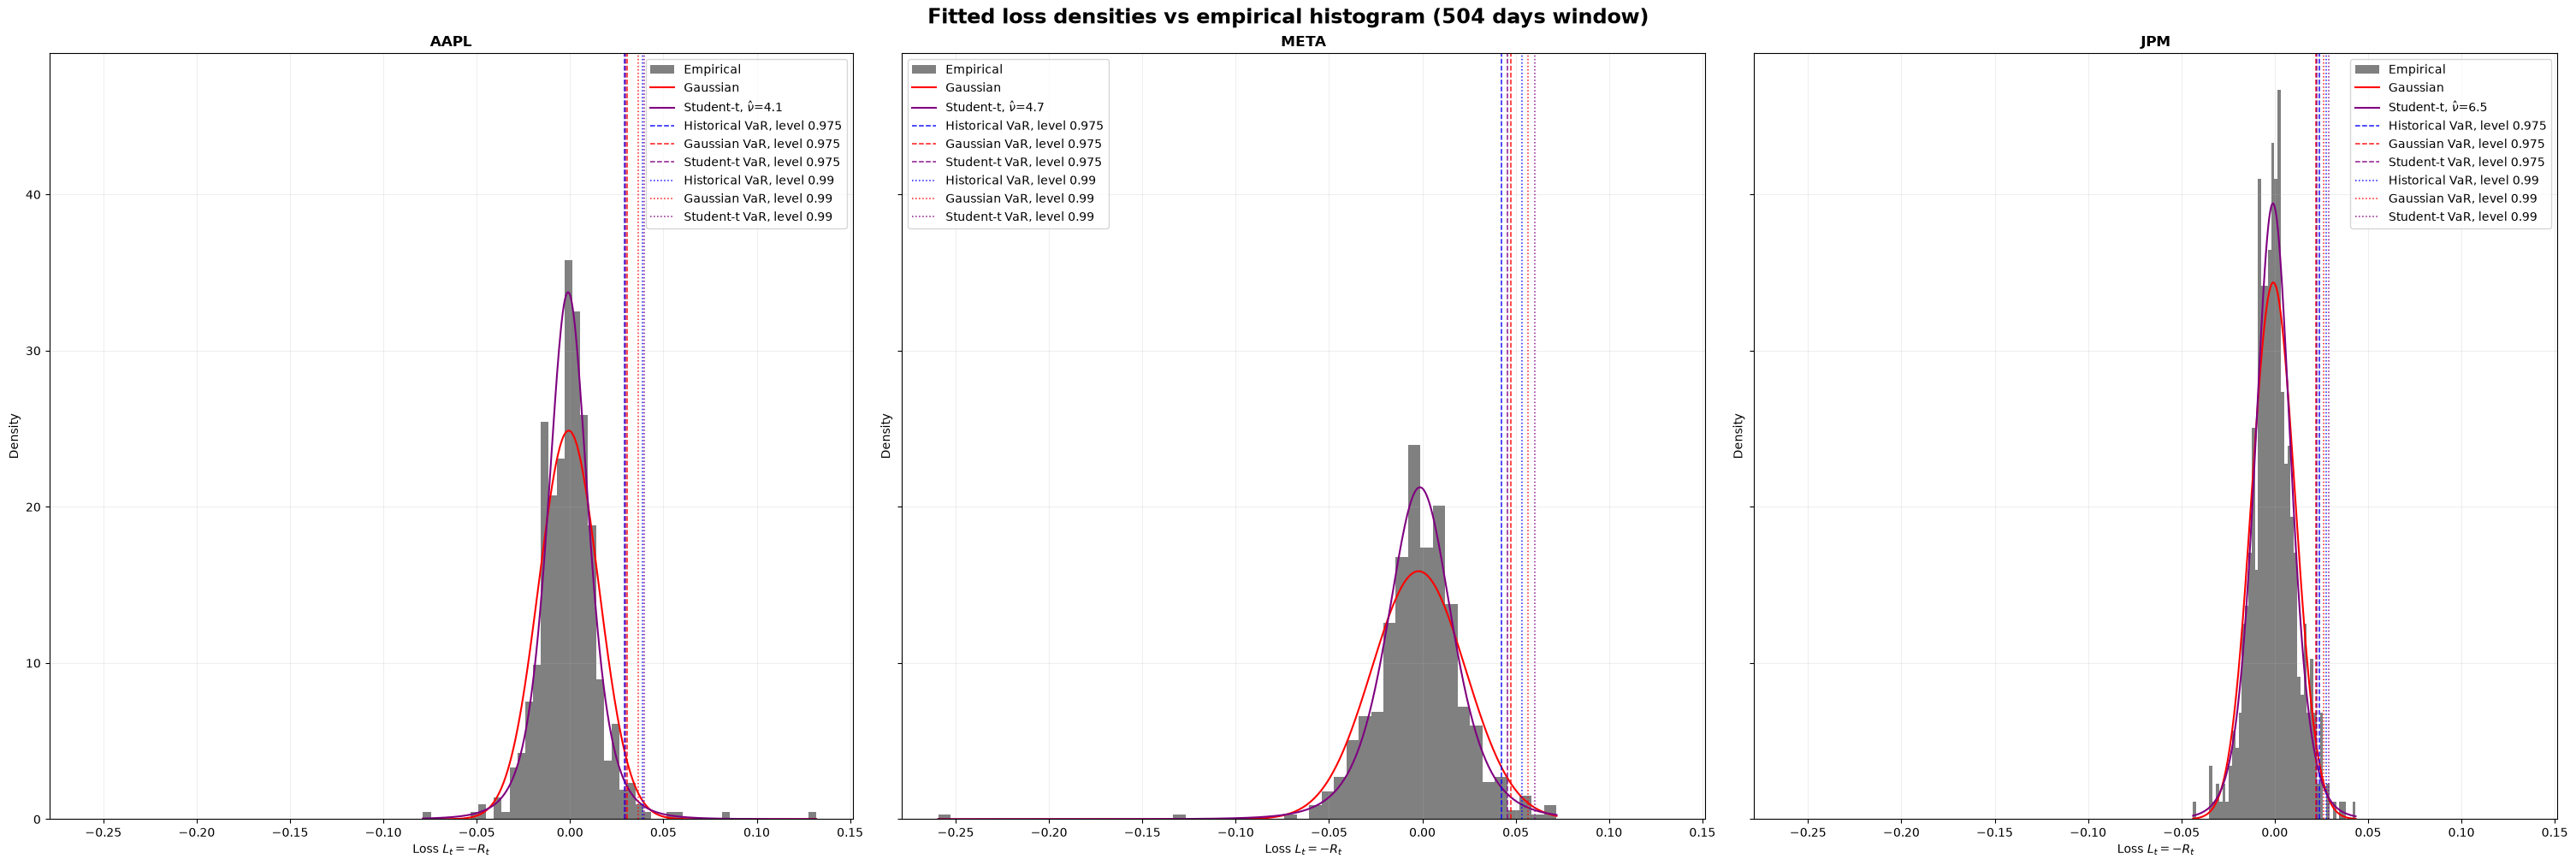

In [ ]:
# Question 2
window_losses = losses.iloc[:WINDOW]          # one column per stock




def historical_var_es(loss_window, alpha):
    """Returns VaR and ES at the alpha level using the historical simulation method."""
    loss_window = np.sort(loss_window)[::-1]
    m = len(loss_window) * (1 - alpha)
    k = int(np.floor(m))
    var = loss_window[k]
    es = (loss_window[:k].sum() + (m - k) * loss_window[k]) / m
    return var, es

def gaussian_var_es(loss_window, alpha):
    """Returns VaR and ES at the alpha level using the gaussian estimation."""
    mu, sigma = loss_window.mean(), loss_window.std(ddof=1)
    z = stats.norm.ppf(alpha)
    var = mu + sigma * z
    es = mu + sigma * stats.norm.pdf(z) / (1 - alpha)
    return var, es

def student_t_var_es(nu, mu, sig, alpha):
    """Returns VaR and ES at the alpha level using the student-t estimation."""
    q = stats.t.ppf(alpha, nu)
    var = mu + sig * q
    es = mu + sig * stats.t.pdf(q, nu) / (1 - alpha) * (nu + q**2) / (nu - 1)
    return var, es

t_params = {s: stats.t.fit(window_losses[s].to_numpy(), method="MLE") for s in TICKERS}

# (a), (b) and (c)
rows = []
for stock in TICKERS:
    loss = window_losses[stock]
    nu, mu_t, sig_t = t_params[stock]
    for alpha in ALPHAS:
        measures = {
            "Historical": historical_var_es(loss, alpha),
            "Gaussian": gaussian_var_es(loss, alpha),
            "Student-t": student_t_var_es(nu, mu_t, sig_t, alpha),
        }
        for method, (var, es) in measures.items():
            rows.append({"method": method, "stock": stock,
                         "alpha": alpha, "VaR": var, "ES": es})

results_df = pd.DataFrame(rows)
t_params_df = pd.DataFrame(t_params, index=["nu", "mu", "sigma"])
display(results_df)
display(t_params_df)

# (d) Overlay of the fitted densities (Gaussian and Student-t) and the empirical histogram

fig, axes = plt.subplots(1, 3, figsize=(30,10), constrained_layout=True, sharey=True, sharex=True)
plt.suptitle("Fitted loss densities vs empirical histogram (504 days window)", fontsize=17, fontweight="bold")

lookup = results_df.set_index(["stock", "alpha", "method"]).sort_index()
methods = ("Historical", "Gaussian", "Student-t")
method_colors = {"Historical": "blue", "Gaussian": "red", "Student-t": "purple"}
linestyle = {0.99: ":",0.975: "--"}

for ax, elem in zip(axes, losses.columns):
    lw = window_losses[elem]
    nu, mu_t, sig_t = t_params[elem]
    grid = np.linspace(lw.min(), lw.max(), 400)
    ax.hist(lw, bins=50, density=True, color="gray", label="Empirical")
    ax.plot(grid, stats.norm.pdf(grid, lw.mean(), lw.std(ddof=1)), lw=1.5, label="Gaussian", color=method_colors["Gaussian"])
    ax.plot(grid, stats.t.pdf(grid, nu, mu_t, sig_t), lw=1.5, label=f"Student-t, $\\hat\\nu$={nu:.1f}", color=method_colors["Student-t"])

    for alpha in ALPHAS:
        for method in methods:
            var = lookup.loc[(elem, alpha, method), "VaR"]
            ax.axvline(var, lw=1.1, ls=linestyle[alpha], alpha=0.9, color=method_colors[method], label=f"{method} VaR, level {alpha}")

    ax.set_title(elem, fontweight="bold")
    ax.set_xlabel("Loss $L_t = -R_t$")
    ax.set_ylabel("Density")
    ax.grid(True, alpha=0.2)
    ax.legend(fontsize=10)
    
plt.savefig("output/Q2_VaR", dpi=800)
plt.show()


The ordering changes with the level. At $\alpha=0.975$ the Gaussian gives the largest VaR for AAPL and META; at $\alpha=0.99$ the Student-t is the largest for all three stocks, and the Gaussian is the smallest (for META, HS is smallest).

Does this match the pdfs? Yes. In the plot the Student-t (purple) is clearly more peaked at the centre and sits below the Gaussian (red) through the shoulders, then runs above it far out in the tail —> the two densities cross. For AAPL and META that crossover falls between the 0.975 and 0.99 quantiles: at 0.975 the Gaussian still carries more mass out there, so its VaR line sits furthest right; by 0.99 the heavier Student-t tail has taken over and its line is furthest right. JPM has the lightest fitted tail ($\hat\nu=6.5$), the red and purple curves are nearly on top of each other so the parametric fits barely separate and the empirical tail (HS) is already the largest at 0.975. In every panel the dashed (0.975) lines sit left of the dotted (0.99) lines, as they must.


## Question 3 -- Backtesting

Forecast every day of the evaluation period `losses.iloc[EVAL_START:]`, each model estimated on the
`WINDOW` days before the forecast day. Historical simulation, Gaussian and Student-$t$ are recomputed
every day. Write the Kupiec, Christoffersen, Acerbi-Szekely, Fissler-Ziegel, pinball-loss and
Diebold-Mariano functions yourself, from the course slides (Kupiec, Christoffersen) and Appendix A of
the project statement (the others); they are
reused unchanged in Questions 4 and 5.

The combined VaR backtest table collects the VaR backtests of Questions 3-5: append one row per
stock, method and level to `backtest_rows` as you go. The ES backtest table ($\alpha=0.975$) collects
the Acerbi-Szekely and Fissler-Ziegel results of Questions 3 and 4 in `es_rows`.

In [55]:
# Helpers

def kupiec(I, alpha):
    n, x = len(I), I.sum()
    phat, p = x / n, 1 - alpha
    lr = 2 * (_term(x, phat / p) + _term(n - x, (1 - phat) / (1 - p)))
    
    return lr, 1 - chi2.cdf(lr, 1)

def christoffersen(I, alpha):
    prev, curr = I[:-1], I[1:]
    n00 = int(((prev==0) & (curr==0)).sum())
    n01 = int(((prev==0) & (curr==1)).sum())
    n10 = int(((prev==1) & (curr==0)).sum())
    n11 = int(((prev==1) & (curr==1)).sum())
    p01, p11 = n01 / (n00 + n01) if (n00 + n01) > 0 else 0.0, n11 / (n10 + n11) if (n10 + n11) > 0 else 0.0
    ppool = (n01 + n11) / (n00 + n01 + n10 + n11)
    l0 = _term(n01 + n11, ppool) + _term(n00 + n10, 1 - ppool)
    l1 = _term(n01, p01) + _term(n00, 1 - p01) + _term(n11, p11) + _term(n10, 1 - p11)
    lrind = -2 * (l0 - l1)
    lruc, _ = kupiec(I, alpha)
    lrcc = lruc + lrind
    return (lrind, 1 - chi2.cdf(lrind, 1)), (lrcc, 1 - chi2.cdf(lrcc, 2))

def pinball_loss(var, alpha, realized):
    S = (np.where(realized <= var, 1, 0) - alpha) * (var - realized)
    return S.mean()

def _term(k, q):
    return k * np.log(q) if k > 0 else 0.0

In [56]:
# Question 3 (a)
from scipy.stats import chi2


eval_loss = losses.iloc[EVAL_START:]        # one column per stock, 2888 forecast days
backtest_rows = []                          # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
es_rows = []                                # dicts: stock, method, Z, p_Z, FZ

METHODS = ["Historical", "Gaussian", "Student-t"]

store = {
    (stock, method, alpha): {"var": [], "es": [], "loss": []}
    for stock in TICKERS
    for method in METHODS
    for alpha in ALPHAS
}
sim_params = {s: {"g_mu": [], "g_sig": [], "t_nu": [], "t_mu": [], "t_sig": []}
              for s in TICKERS}


for t in range(EVAL_START, len(losses)):
    for stock in TICKERS:
        window = losses[stock].iloc[t-WINDOW:t]
        realized = losses[stock].iloc[t]
        nu, mu_t, sig_t = stats.t.fit(window.to_numpy(), method="MLE")
        sp = sim_params[stock]
        sp["g_mu"].append(window.mean());   sp["g_sig"].append(window.std(ddof=1))
        sp["t_nu"].append(nu); sp["t_mu"].append(mu_t); sp["t_sig"].append(sig_t)


        for alpha in ALPHAS:
            forecasts = {
                "Historical": historical_var_es(window, alpha),
                "Gaussian": gaussian_var_es(window, alpha),
                "Student-t": student_t_var_es(nu, mu_t, sig_t, alpha),
            }

            for method, (var, es) in forecasts.items():
                s = store[(stock, method, alpha)]
                s["var"].append(var)
                s["es"].append(es)
                s["loss"].append(realized)

for s in TICKERS:
    for k in sim_params[s]:
        sim_params[s][k] = np.asarray(sim_params[s][k])


for (stock, method, alpha), s in store.items():
    var = np.array(s["var"])
    es = np.array(s["es"])
    loss = np.array(s["loss"])
    I = (loss > var).astype(int)

    lr_uc, p_uc = kupiec(I, alpha)
    (lr_ind, p_ind), (lr_cc, p_cc) = christoffersen(I, alpha)
    pb = pinball_loss(var, alpha, loss)

    backtest_rows.append({
        "stock": stock, "method": method, "alpha": alpha,
        "x": int(I.sum()), "expected": len(I) * (1 - alpha), "hit": I.mean(),
        "p_uc": p_uc, "p_ind": p_ind, "p_cc": p_cc, "pinball_bp": pb * 1e4
    })

backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()
backtest_table99 = backtest_table.loc[0.99]
backtest_table975 = backtest_table.loc[0.975]
display(backtest_table)

x  expected       hit          p_uc         p_ind  \
alpha stock method                                                            
0.975 AAPL  Gaussian    105     72.20  0.036357  2.472590e-04  4.065558e-04   
            Historical   86     72.20  0.029778  1.101693e-01  4.478473e-03   
            Student-t   103     72.20  0.035665  5.530672e-04  6.200267e-05   
      JPM   Gaussian     95     72.20  0.032895  9.490477e-03  8.680740e-06   
            Historical   83     72.20  0.028740  2.084772e-01  3.886088e-08   
            Student-t    92     72.20  0.031856  2.349290e-02  6.250520e-07   
      META  Gaussian     78     72.20  0.027008  4.948864e-01  2.195534e-04   
            Historical   75     72.20  0.025970  7.401494e-01  1.550802e-02   
            Student-t    89     72.20  0.030817  5.320782e-02  3.797885e-04   
0.990 AAPL  Gaussian     62     28.88  0.021468  7.703174e-08  1.172397e-02   
            Historical   41     28.88  0.014197  3.299351e-02  1.378501e-01   
            Student-t    41     28.88  0.014197  3.299351e-02  1.378501e-01   
      JPM   Gaussian     64     28.88  0.022161  1.504798e-08  6.722479e-07   
            Historical   42     28.88  0.014543  2.157171e-02  1.066865e-06   
            Student-t    47     28.88  0.016274  1.890508e-03  5.674129e-06   
      META  Gaussian     52     28.88  0.018006  1.014632e-04  2.300373e-03   
            Historical   40     28.88  0.013850  4.939976e-02  1.252902e-01   
            Student-t    37     28.88  0.012812  1.455804e-01  9.219384e-02   

                                p_cc  pinball_bp  
alpha stock method                                
0.975 AAPL  Gaussian    2.335407e-06   13.747931  
            Historical  4.915692e-03   13.600955  
            Student-t   8.448838e-07   13.725780  
      JPM   Gaussian    1.751680e-06   13.206539  
            Historical  1.251531e-07   13.022655  
            Student-t   3.112904e-07   13.296728  
      META  Gaussian    8.580230e-04   18.321232  
            Historical  5.059483e-02   18.261721  
            Student-t   2.792959e-04   18.285864  
0.990 AAPL  Gaussian    2.236607e-08    7.658084  
            Historical  3.425387e-02    7.244271  
            Student-t   3.425387e-02    7.223108  
      JPM   Gaussian    4.775069e-13    7.581377  
            Historical  4.837162e-07    7.216464  
            Student-t   2.702259e-07    7.335284  
      META  Gaussian    5.024843e-06   10.671943  
            Historical  4.478807e-02   10.372436  
            Student-t   8.401150e-02   10.507807

In [57]:
# (b)
p_cols = ["p_uc", "p_ind", "p_cc"]
backtest_bool = backtest_table.copy()
backtest_bool[p_cols] = backtest_table[p_cols] >= 0.05
display(backtest_bool.loc[:, p_cols])
# True means failed to reject the null
# and False means rejecting the null

p_uc  p_ind   p_cc
alpha stock method                         
0.975 AAPL  Gaussian    False  False  False
            Historical   True  False  False
            Student-t   False  False  False
      JPM   Gaussian    False  False  False
            Historical   True  False  False
            Student-t   False  False  False
      META  Gaussian     True  False  False
            Historical   True  False   True
            Student-t    True  False  False
0.990 AAPL  Gaussian    False  False  False
            Historical  False   True  False
            Student-t   False   True  False
      JPM   Gaussian    False  False  False
            Historical  False  False  False
            Student-t   False  False  False
      META  Gaussian    False  False  False
            Historical  False   True  False
            Student-t    True   True   True

Every coverage failure is in the same direction, i.e. too many
exceptions (every hit rate exceeds its target), so the models under-forecast risk, and
the Gaussian is the worst offender. At $\alpha=0.975$ the Gaussian fails for AAPL and JPM
($p_{uc}=2.5\mathrm{e}{-4},\,9.5\mathrm{e}{-3}$) and Student-t fails for AAPL and JPM
($5.5\mathrm{e}{-4},\,0.023$).
Historical passes coverage on all three stocks ($p_{uc}=0.11,\,0.21,\,0.74$). 
At $\alpha=0.99$ coverage collapses almost everywhere: the Gaussian fails all three at $p_{uc}\sim10^{-8}$ (62–64 exceptions vs 28.9 expected),
and Historical and Student-t fail for AAPL and JPM as well. The lone clean pass is META Student-t at 0.99 ($p_{uc}=0.15$), the only (stock, method, level) that passes all three tests.


At $\alpha=0.975$ all nine rows fail independence ($p_{ind}<0.05$). The exceptions cluster, exactly as expected from unconditional models during volatility clustering (e.g. 2020). At $\alpha=0.99$ independence is rejected less
often — it passes for AAPL (Historical, Student-t: $p_{ind}=0.14$) and META (Historical $0.13$, Student-t $0.09$) but this is partly low power as exceptions are rare at 0.99, so there are few consecutive pairs to detect clustering with.

Where Kupiec and conditional coverage disagree, the cases are all at
$\alpha=0.975$, where coverage passes but conditional coverage fails:
AAPL Historical ($p_{uc}=0.11$ but $p_{cc}=4.9\mathrm{e}{-3}$), JPM Historical
($0.21$ vs $1.3\mathrm{e}{-7}$), META Gaussian ($0.49$ vs $8.6\mathrm{e}{-4}$) and META Student-t ($0.053$ vs $2.8\mathrm{e}{-4}$). In every one of these the independence component is responsible: the models produce roughly the right number of exceptions but bunch them in time, and that clustering is what makes the conditional-coverage test fail.
Where coverage itself fails (most rows at 0.99), CC fails too, so no disagreement in this direction.


In [ ]:
# (c)
AZ_ALPHA = 0.975
n_fore = len(losses) - EVAL_START

Wmatrix = {s: np.stack([losses[s].iloc[EVAL_START+j-WINDOW:EVAL_START+j].to_numpy()
                     for j in range(n_fore)]) for s in TICKERS}

def az_Z(loss, var, es, alpha):
    I = (loss > var).astype(float)
    return np.sum(loss * I / es) / (len(loss) * (1 - alpha)) - 1

def simulate_losses(stock, method, M):
    p, n = sim_params[stock], n_fore
    if method == "Gaussian":
        return p["g_mu"][None, :] + p["g_sig"][None, :] * rng.standard_normal((M, n))
    if method == "Student-t":
        T = stats.t.rvs(df=p["t_nu"][None, :], size=(M, n), random_state=rng)
        return p["t_mu"][None, :] + p["t_sig"][None, :] * T
    if method == "Historical":
        idx = rng.integers(0, WINDOW, size=(M, n))
        return Wmatrix[stock][np.arange(n)[None, :], idx]

def az_test(loss, var, es, alpha, sim_losses):
    Z = az_Z(loss, var, es, alpha)
    I_sim = (sim_losses > var).astype(float)                 
    Z_sim = (sim_losses * I_sim / es).sum(axis=1) / (len(loss) * (1 - alpha)) - 1
    return Z, np.mean(Z_sim >= Z)                            

for stock in TICKERS:
    for method in METHODS:
        s = store[(stock, method, AZ_ALPHA)]
        var, es, loss = np.array(s["var"]), np.array(s["es"]), np.array(s["loss"])
        sims = simulate_losses(stock, method, M_SIM)
        Z, p_Z = az_test(loss, var, es, AZ_ALPHA, sims)
        es_rows.append({"stock": stock, "method": method, "Z": Z, "p_Z": p_Z})

es_table = pd.DataFrame(es_rows).set_index(["stock", "method"]).sort_index()
display(es_table)


Z     p_Z
stock method                      
AAPL  Gaussian    0.780308  0.0000
      Historical  0.247633  0.0115
      Student-t   0.372596  0.0073
JPM   Gaussian    0.731701  0.0000
      Historical  0.250464  0.0109
      Student-t   0.348900  0.0131
META  Gaussian    0.494670  0.0001
      Historical  0.125152  0.1103
      Student-t   0.327334  0.0097

Every method gives $Z>0$. Realized tail losses, scaled by the forecast ES, exceed what the model predicts, so all three under-estimate ES which is consistent with the excess exceptions found in (b). The ranking is the same for all three stocks. RThe Gaussian is worst ($Z\approx0.49$–$0.78$, $p_Z\approx0$), then Student-t ($Z\approx0.33$–$0.37$,
$p_Z\approx0.007$–$0.013$), then Historical, the least bad ($Z\approx0.13$–$0.25$).
At the 5% level the Gaussian and Student-t ES are rejected for every stock. Historical is rejected for AAPL ($p_Z=0.011$) and JPM ($p_Z=0.011$) but passes for META ($p_Z=0.110$).
The Gaussian's thin tails understate ES the most and  historical, which uses the empirical tail of
the window comes closest.

Why does the simulated distribution depend on the method being tested? $Z$ has no closed-form null, so its
distribution is generated by redrawing the losses under each method's own forecast distribution while holding that method's VaR/ES fixed. Those distributions differ in shape
and tail thickness so the simulated spread of $Z^{(m)}$ and the reference differs for each method. Two methods with the same observed $Z$ could therefore get different p-values as each is tested against the null implied by its own model. 

In [ ]:
# (d)
import statsmodels.api as sm

FZ_ALPHA = 0.975

def fz_score(var, es, loss, alpha):
    I = (loss > var).astype(float)
    return I / ((1 - alpha) * es) * (loss - var) + var / es + np.log(es) - 1

def diebold_mariano(d, lags=NW_LAGS):
    d = np.asarray(d, dtype=float)
    res = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return res.params[0], res.tvalues[0], res.pvalues[0]


fz_days = {}
for stock in TICKERS:
    for method in METHODS:
        s = store[(stock, method, FZ_ALPHA)]
        var, es, loss = np.array(s["var"]), np.array(s["es"]), np.array(s["loss"])
        fz_days[(stock, method)] = fz_score(var, es, loss, FZ_ALPHA)

fz_mean = {k: v.mean() for k, v in fz_days.items()}
es_table["FZ"] = [fz_mean[idx] for idx in es_table.index]


dm_rows = []
for stock in TICKERS:
    ranked = sorted(METHODS, key=lambda m: fz_mean[(stock, m)])          
    best, second, third = ranked
    d = fz_days[(stock, best)] - fz_days[(stock, second)]                
    mean_d, dm_t, dm_p = diebold_mariano(d)
    dm_rows.append({
        "stock": stock,
        "best": best,     "FZ_best":   fz_mean[(stock, best)],
        "second": second, "FZ_second": fz_mean[(stock, second)],
        "third": third,   "FZ_third":  fz_mean[(stock, third)],
        "mean_diff": mean_d, "DM_t": dm_t, "DM_p": dm_p,
    })

dm_table = pd.DataFrame(dm_rows).set_index("stock")
display(es_table, dm_table)



Z     p_Z        FZ
stock method                                
AAPL  Gaussian    0.780308  0.0000 -2.834047
      Historical  0.247633  0.0115 -2.910412
      Student-t   0.372596  0.0073 -2.897872
JPM   Gaussian    0.731701  0.0000 -2.862404
      Historical  0.250464  0.0109 -2.959067
      Student-t   0.348900  0.0131 -2.916310
META  Gaussian    0.494670  0.0001 -2.536598
      Historical  0.125152  0.1103 -2.617383
      Student-t   0.327334  0.0097 -2.595165

,best,FZ_best,second,FZ_second,third,FZ_third,mean_diff,DM_t,DM_p
stock,,,,,,,,,
AAPL,Historical,-2.910412,Student-t,-2.897872,Gaussian,-2.834047,-0.012540,-1.181788,0.237290
META,Historical,-2.617383,Student-t,-2.595165,Gaussian,-2.536598,-0.022218,-1.406152,0.159679
JPM,Historical,-2.959067,Student-t,-2.916310,Gaussian,-2.862404,-0.042757,-2.579553,0.009893


By average FZ score the ranking is identical for all three stocks:
Historical < Student-t < Gaussian.

The FZ ranking matches (c). Historical is the least bad, the
Gaussian the worst. But the Diebold–Mariano test shows that Historical over Student-t is significant only for JPM ($p=0.010$). For AAPL and META the mean score difference is not distinguishable from zero ($p=0.24,\,0.16$), so on this sample Historical and Student-t are
statistically tied.

DM tests whether the difference in average
FZ score between two methods is zero, using a Newey–West HAC standard error to account for the autocorrelation in the daily score differences. So a significant result (JPM) says that Historical's lower score reflects a relative accuracy advantage over Student-t for the joint (VaR, ES) objective. It does not say that the winning model is correct as DM is only a pairwise comparisond. Note that the AS test in (c) rejected both methods for AAPL and JPM, so the better model can
still be a poorly specified one. And non-significant results do not necessarily mean that the two models are truly equivalent. The verdict is also specific to only the FZ loss and says nothing about coverage or independence, which are
judged by the tests in (a)–(b).


## Question 4 -- AR-GARCH conditional VaR and ES

(a) Mean model, full sample: fit AR($p$), $p=0,\dots,3$, with constant variance on the same
observations, e.g. `ARX(y, lags=p, hold_back=3)` from `arch.univariate`; pick $p$ by BIC (also report
AIC); Ljung-Box on the residuals (`model_df=p`) and on their squares.
(b) Fit `arch_model(y, mean="AR", lags=p, vol="GARCH", p=1, q=1, dist=..., hold_back=3)` on the full
sample with `dist="normal"` and `dist="t"` (use `mean="Constant"` if $p=0$); Ljung-Box on the
standardized residuals of the Gaussian fit (`model_df=p`) and their squares (`model_df=2`).
(c) Re-estimate both inside the rolling scheme every `REFIT` days with the same $p$. Between refits,
keep the parameters fixed but advance $\hat\mu_t$ and $\hat\sigma_t$ daily with the realized
returns (for example with `arch_model(...).fix(params)` on the data up to the forecast day). Fit on
returns in percent (`100 * R`) to avoid `arch` convergence warnings, and convert the forecasts back.
(d) Backtest both and add them to the two tables.

In [93]:
# Question 4
from arch import arch_model


## Question 5 -- Quantile regression

Same evaluation period, window and refit days as Question 4. One model per stock and level, VaR only;
the two features are built by `make_features` below, both using information up to $t-1$; the target
is the loss $L_t$. Rows with an undefined feature (the first 20 days) are dropped from the training
window. Linear quantile regression, e.g.
`sm.QuantReg(y, sm.add_constant(X)).fit(q=alpha, max_iter=5000)`.

In [94]:
# Question 5
import statsmodels.api as sm


def make_features(ret: pd.Series) -> pd.DataFrame:
    """Features x_{t-1} for the forecast of day t: row t uses information up to t-1 only."""
    feat = pd.DataFrame(index=ret.index)
    feat["absR_lag1"] = ret.shift(1).abs()
    feat["sigma20"] = ret.shift(1).rolling(20).std(ddof=1)
    return feat


# After (a) and (b): the combined VaR backtest table, one table per level
# backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()


## Question 6 -- Extreme value theory

One static fit on each stock's full-sample log-loss series, with threshold $u$ the empirical 95%
quantile. `scipy.stats.genpareto.fit(excesses, floc=0)` may be used for the GPD maximum-likelihood
step.

In [13]:
# Question 6
from scipy.stats import genpareto
full_loss = losses                          # one column per stock


### (a)

Supposing stationarity, every $L_t$ has the same marginal distribution regardless of dependence. The GPD fit is applied to the excess of that marginal distribution over a threshold u. It estimates the tail of the unconditional marginal distribution of $L_t$  i.e. the excess distribution $F_u$.

### (b)

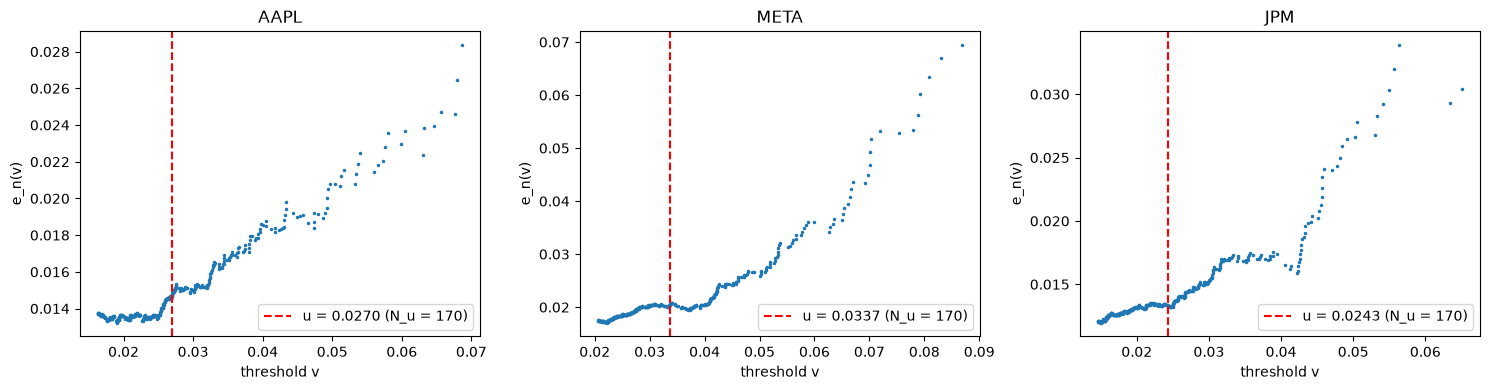

In [16]:
# Plot
# We want to plot the mean of (Xi - v) for i in [2, n]


K = 400
MIN_EXC = 10

fig, axes = plt.subplots(1, len(full_loss.columns), figsize=(15, 4))
e, thresholds, u_dict, Nu_dict = {}, {}, {}, {}

for ax, name in zip(axes, full_loss.columns):

    data = full_loss[name].dropna()
    x = np.sort(data.values)[::-1] # Sort in descending order

    i = np.arange(1, len(x)) # Generate indexes
    e_vals = np.cumsum(x)[:-1]/i - x[1:] # Compute excess mean
    v_vals = x[1:] # Thresholds

    # Create a mask for the upper tail with min exceendance count
    mask = (i <= K) & (i >= MIN_EXC)
    e[name], thresholds[name] = e_vals[mask], v_vals[mask] # Save in dictionnary


    u = data.quantile(0.95, interpolation="lower") # Set the reference 95 % quantile
    u_dict[name] = u
    Nu_dict[name] = int((data > u).sum()) # Compute number of exceedances

    # Plot
    ax.plot(thresholds[name], e[name], ".", ms=3)
    ax.axvline(u, color="red", ls="--", label=f"u = {u:.4f} (N_u = {Nu_dict[name]})")
    ax.set_title(name); ax.set_xlabel("threshold v"); ax.set_ylabel("e_n(v)")
    ax.legend()

plt.tight_layout()
plt.savefig("output/Q6_EVT")
plt.show()

### (c) Fitting a GPD to the excess

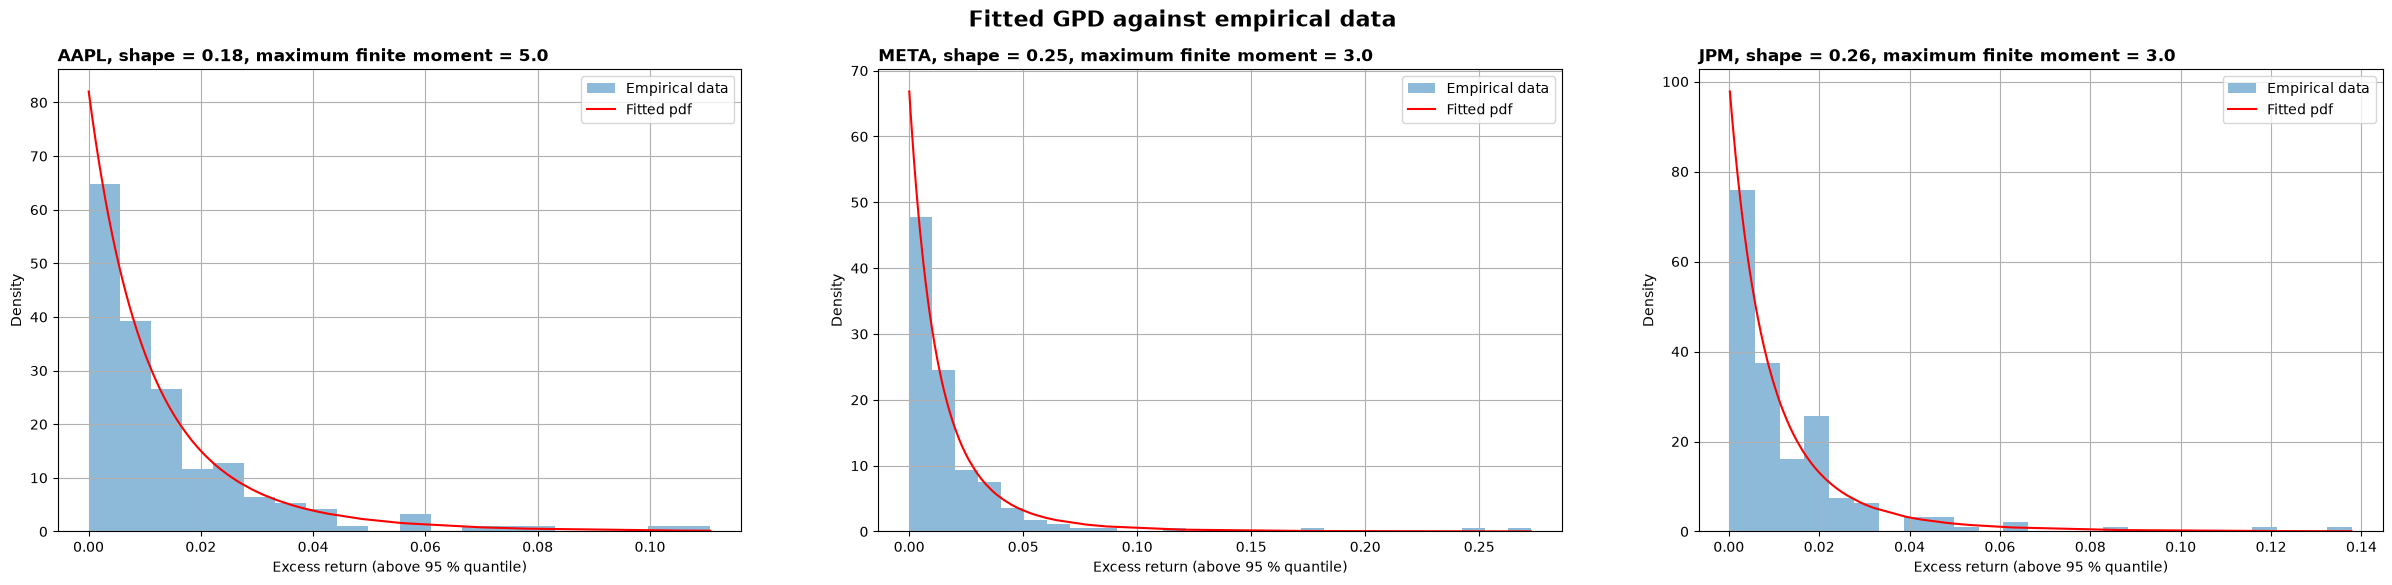

In [112]:
# We want to fit a GPD using maximum likelihood considering the threshold q-95 of the data.
# We use the genpareto.fit method (use the MLE per default)

# 1. Get the data for the fit and graphical comparison
# Recall u_dict contains the q-95 for each stock

params = {
    #  For a GPD : (shape, location, scale) (order returned by scipy.fit)
}

names = full_loss.columns.tolist()

fig, axes = plt.subplots(
        1, len(names),
        figsize = (len(names) * 10, 6)
    )

plt.suptitle('Fitted GPD against empirical data', fontsize = 16, fontweight = 'bold')

for i in range(len(names)):

    name = names[i]

    tmp = full_loss[name] 

    # 1.1 
    q95 = u_dict[name] # Get the quantile (i.e. threshold)
    exced = tmp[tmp > q95] - q95 # Get exceedance data
    exced = exced.sort_values() # Sort values for later plotting cleanliness
    param = genpareto.fit(exced, floc = 0) # Fit the model, set location at 0

    # Save param
    params[name] = param

    # 1.2 Comparing empirical and fitted

    # Get pdf 
    y = genpareto.pdf(exced, param[0], param[1], param[2])

    # Graphical display
    ax = axes[i]

    ax.set_title(
        label =  f'{name}, shape = {param[0]:.2f}, maximum finite moment = {1 // param[0]}',
        loc = 'left', fontweight = 'bold'
    )

    ax.set(
        xlabel = 'Excess return (above 95 % quantile)', 
        ylabel = 'Density'
    )

    ax.hist(exced, density = True, bins = 'auto', histtype='stepfilled', label = 'Empirical data', alpha = 0.5)
    ax.plot(exced, y, label='Fitted pdf', color = 'red') 
    ax.grid()
    ax.legend()

plt.savefig('output/Q6_3_fittedGPD')
plt.show()


k-th moment are finite as long as  $k < \frac{1}{\xi}$ where $\xi$ is the shape parameter (i.e. controls the tail heaviness). We observe that only AAPL will have a finite 4-th moment. Thus the assumption for the question 1 (b) is wrong. For META and JPM we cannot use the Ljung-Box test to refute the null hypothesis on $R_t^2$.

### (d)

In [ ]:
# Recall Nu_dict contains number of exceedance 
# and params contains the fitted GPD parameters

compare = {}
var_es_results = []

for name in full_loss:

    n = full_loss[name].shape[0]
    u = u_dict[name]
    Nu = Nu_dict[name]
    param = params[name]
    shape, scale = param[0], param[2]


    # 1. First we compute VaR and ES through the CDF
    r = n/Nu * (1 - DEEP_ALPHA)
    var_cdf = u + genpareto.isf(r, c=shape, loc=0, scale=scale)
    es_cdf = var_cdf + (scale + shape *(var_cdf - u))/(1 - shape)

    # 2. Compute VaR and ES through A.5 formulas
    # Use DEEP_ALPHA

    var_direct = u + scale/shape * ((n * (1 - DEEP_ALPHA)/Nu)**(-shape) - 1)
    es_direct = var_direct/(1 - shape) + (scale - u * shape)/(1 - shape)

    compare[name] = {
        "VaR from fitted CDF": var_cdf,
        "VaR direct": var_direct,
        "ES from fitted tail": es_cdf,
        "ES direct": es_direct,
    }

    # 4. Save results
    var_es_results.append({
        'method' : 'Fitted GPD', 'stock' : name,
        'alpha' : DEEP_ALPHA, 'VaR' : var_cdf, 'ES' : es_cdf
    })

display(pd.DataFrame(compare))


# Question 6 (e) (same code as question 2)
window_losses = losses        # one column per stock
alphas = [DEEP_ALPHA]

# (a) Gaussian
for elem in window_losses:
    mu = window_losses[elem].mean()
    sigma = window_losses[elem].std(ddof=1)
    for alpha in alphas:
        var = mu + sigma * stats.norm.ppf(alpha)
        es = mu + sigma * stats.norm.pdf(stats.norm.ppf(alpha)) / (1 - alpha)
        method = "Gaussian"
        var_es_results.append({
            "method": method, "stock": elem, "alpha": alpha,
            "VaR": var, 
            "ES": es,
        })

# (b) Student-t
t_params = {}
for elem in window_losses:
    lw = window_losses[elem]
    nu, mu_t, sig_t = stats.t.fit(lw.to_numpy())
    t_params[elem] = (nu, mu_t, sig_t)
    for alpha in alphas:
        q = stats.t.ppf(alpha, nu)
        var = mu_t + sig_t * q
        es = mu_t + sig_t * stats.t.pdf(q, nu) / (1.0 - alpha) * (nu + q**2) / (nu - 1.0)
        method = "Student-t"
        var_es_results.append({
            "method": method, "stock": elem, "alpha": alpha,
            "VaR": var,
            "ES": es
        })

var_es_results_df = pd.DataFrame(var_es_results).set_index("method")


,AAPL,META,JPM
VaR from fitted CDF,0.095757,0.133871,0.091260
VaR direct,0.095757,0.133871,0.091260
ES from fitted tail,0.125446,0.188130,0.127706
ES direct,0.125446,0.188130,0.127706


In [179]:
order = ["Gaussian", "Student-t", "Fitted GPD"]

# Long format -> one row per stock, columns (measure, method), in percent
df = var_es_results_df.reset_index()
tbl = (df.pivot(index="stock", columns="method", values=["VaR", "ES"])
         .reindex(columns=order, level=1) * 100)

# 1) Main comparison table (values in % of price)
print(f"Full-sample {DEEP_ALPHA:.1%} VaR and ES (in % of price)")
display(tbl.round(2))

# 2) Percent difference of Gaussian and Student-t relative to the GPD
rel = pd.DataFrame({
    (m, meth): (tbl[(m, meth)] / tbl[(m, "Fitted GPD")] - 1) * 100
    for m in ["VaR", "ES"] for meth in ["Gaussian", "Student-t"]
})
print("Difference to the GPD estimate (percent of the GPD value)")
display(rel.round(1))

# 3) Which model gives the lowest VaR and ES, per stock
lowest = pd.DataFrame({
    "Lowest VaR": tbl["VaR"].idxmin(axis=1),
    "Lowest ES":  tbl["ES"].idxmin(axis=1),
})
print("Lowest model per stock")
display(lowest)

Full-sample 99.9% VaR and ES (in % of price)


VaR                            ES                     
method Gaussian Student-t Fitted GPD Gaussian Student-t Fitted GPD
stock                                                             
AAPL       5.41     10.42       9.58     5.91     15.17      12.54
JPM        4.97      9.48       9.13     5.42     13.93      12.77
META       7.35     13.71      13.39     8.02     20.27      18.81

Difference to the GPD estimate (percent of the GPD value)


VaR                 ES          
      Gaussian Student-t Gaussian Student-t
stock                                      
AAPL     -43.5       8.9    -52.9      20.9
JPM      -45.5       3.9    -57.5       9.1
META     -45.1       2.4    -57.4       7.7

Lowest model per stock


,Lowest VaR,Lowest ES
stock,,
AAPL,Gaussian,Gaussian
JPM,Gaussian,Gaussian
META,Gaussian,Gaussian
